<div style="background:#2f7d58;color:white;padding:22px 26px;border-radius:12px;">
<h1 style="margin:0;color:white;">Project · Factorization Machine (X2)</h1>
<h2 style="margin:8px 0 0 0;color:white;font-weight:500;">Speed Dating Experiment — a reciprocal factorization machine recommender</h2>
</div>

**Course:** Recommender Systems — Master Applied Data Science and AI
**Project:** A reciprocal recommender system for speed dating
**Authors:** Barnard Alison · Kohler Andrin · Tabalae Petronela · Sever Alin (HSLU)
**Input:** `Data/features/speed_dating_features.csv` · **Previous steps:** `01_Speed_Dating_EDA.ipynb`, `02_Speed_Dating_Feature_Engineering.ipynb`
**Code:** model, training and metric logic lives in `sd_fm.py` — this notebook narrates and verifies it

> **How to run.** Python 3.11 with `pip install -r requirements.txt` (PyTorch included). Open
> from the **repository root**, so that `sd_features.py`/`sd_fm.py` are importable and the
> feature CSV resolves. Deterministic given `SEED = 42`. Read `02_Speed_Dating_Feature_Engineering.ipynb`
> Section 15 first — every design decision here answers to that hand-off.

## What this notebook produces

**X2**, the factorization machine specified by the proposal deck: a model that predicts
`P(dec=1)` for each directed encounter, combines the two directions of every pair into a match
probability by harmonic mean, and evaluates the resulting ranking under the project's fixed
21-fold leave-one-wave-out protocol (NDCG@3, Precision@3, MRR, Coverage@3).

| Artefact | What it is |
|---|---|
| `sd_fm.py` | The importable module — `FactorizationMachine`, `train_fm`, `select_hyperparams`, `run_lowo_fm`, `evaluate_lowo_rankings`, and the four ranking-metric functions |
| This notebook | Narrates the model, verifies the metric functions on a toy example, runs the hyperparameter search once, runs the 21-fold evaluation, and reports the result |

## What this notebook does *not* do

Baseline **Z** and **X1** (cluster-based) are not built here — this notebook is X2 only. No
feature is redefined: `FEATURES_ALL` and `fit_preprocessor`/`transform` come from `sd_features.py`
unchanged, exactly as Section 15 of notebook 02 hands them off.

> The FM never sees `iid`/`pid` as
> identity — every held-out participant is a **total cold start** (0 of 551 have training
> history in any of the 21 folds, EDA §15), so the model generalises only through the feature
> vector. Preprocessing is refit on training waves only, inside every one of the 21 folds — the
> same discipline notebook 02 §12 established, applied here to a real downstream model instead of
> a demonstration.


## 1. Setup

Same seed and plotting conventions as notebooks 01 and 02. `sd_fm` is the project module that
holds the FM model, training loop, hyperparameter search, and all four ranking metrics.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score

import sd_features as sf
import sd_fm as fm

SEED = sf.SEED
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

GREEN, RED, LIGHT = "#2f7d58", "#c44e34", "#7bb59a"

feat = sf.load_features()
print(f"module: {Path(fm.__file__).name}")
print(f"feat:   {feat.shape[0]:,} directed encounters x {feat.shape[1]} columns, "
      f"{feat['wave'].nunique()} waves")
display(feat.head())

module: sd_fm.py
feat:   8,368 directed encounters x 102 columns, 21 waves


,iid,pid,wave,gender,order,dec,dec_o,match,age,imprace,imprelig,exphappy,go_out,date,age_p,imprace_p,imprelig_p,exphappy_p,go_out_p,date_p,...,shopping_p,yoga_p,age_diff,age_gap,samerace,race_importance,same_field,same_goal,same_career,go_out_diff,date_diff,int_corr,int_sim_pearson,int_sim_cosine,compat_a2b,compat_b2a,compat_harmonic,compat_gap_l1,shar_x_intcorr,shar_x_intcorr_p
0,1,11,1,0,4,1,0,0,21.0000,2.0000,4.0000,3.0000,1.0000,7.0000,27.0000,7.0000,3.0000,7.0000,4.0000,5.0000,...,5.0000,1.0000,6.0000,-6.0000,0,0.0000,0.0000,0.0000,NaN,3.0000,2.0000,0.1400,0.2701,0.8341,7.5294,7.2632,7.3939,0.1208,0.0210,0.0070
1,1,12,1,0,3,1,0,0,21.0000,2.0000,4.0000,3.0000,1.0000,7.0000,22.0000,1.0000,1.0000,7.0000,1.0000,1.0000,...,5.0000,5.0000,1.0000,-1.0000,0,0.0000,1.0000,0.0000,NaN,0.0000,6.0000,0.5400,0.5545,0.8931,9.2353,6.8000,7.8327,0.1151,0.0810,0.0000
2,1,13,1,0,10,1,1,1,21.0000,2.0000,4.0000,3.0000,1.0000,7.0000,22.0000,3.0000,5.0000,3.0000,1.0000,7.0000,...,8.0000,1.0000,1.0000,-1.0000,1,2.0000,1.0000,1.0000,NaN,0.0000,0.0000,0.1600,0.3132,0.8502,6.1765,7.4091,6.7369,0.2431,0.0240,0.0192
3,1,14,1,0,5,1,1,1,21.0000,2.0000,4.0000,3.0000,1.0000,7.0000,23.0000,1.0000,1.0000,8.0000,1.0000,4.0000,...,6.0000,1.0000,2.0000,-2.0000,0,0.0000,1.0000,1.0000,NaN,0.0000,3.0000,0.6100,0.6606,0.9147,9.0000,7.3158,8.0710,0.1412,0.0915,0.0305
4,1,15,1,0,7,1,1,1,21.0000,2.0000,4.0000,3.0000,1.0000,7.0000,24.0000,3.0000,1.0000,5.0000,1.0000,4.0000,...,2.0000,1.0000,3.0000,-3.0000,0,0.0000,1.0000,0.0000,NaN,0.0000,3.0000,0.2100,0.3392,0.8522,7.8235,7.1250,7.4579,0.1207,0.0315,0.0420


## 2. What this notebook inherits from notebook 02 and the proposal deck

| # | Constraint | Source | What it forces here |
|---|---|---|---|
| 1 | **Total cold start** — 0 of 551 held-out participants have any training history, in all 21 folds | EDA §15 | The FM must generalise through `FEATURES_ALL`, the feature vector. `iid`/`pid` are join keys only, never model inputs |
| 2 | **Preprocessing must be fit on training waves only** | Notebook 02 §12/§15 | `sd_fm.run_lowo_fm` calls `sf.fit_preprocessor` fresh inside its loop, once per fold — never on the full table |
| 3 | **Reciprocal combination is harmonic mean**, not product | Proposal deck, quoted in EDA §0/§15.3 | `sd_fm.combine_harmonic` — the same construction as `compat_harmonic` in `sd_features.py`, applied to model outputs |
| 4 | **Hyperparameters are chosen once**, not tuned per fold | Design decision for this notebook | Section 5 below: one inner validation split, reused unchanged for all 21 outer fits |
| 5 | **Ranking relevance is `match`, not `dec`** | Notebook 02 §15.2 / EDA §10 | `dec` trains the directional model; `match` is only ever a ranking-evaluation label |
| 6 | **Users with no true match are excluded from NDCG@3/Precision@3/MRR** | EDA §10, stated as a decision the evaluator must make explicit | `evaluate_user_rankings(..., skip_zero_relevant=True)` — the convention chosen here, stated again in Section 7 |

**Full preprocessing coverage.** All 95 `FEATURES_ALL` columns reach the FM. `race_importance`
needs its own `x/10` divisor — it is `imprace × samerace`, so 0 is a real value (a different-race
pair) rather than out-of-range — and is routed to `sd_features`' `minmax_0_10` block accordingly.
The cell below verifies that no `FEATURES_ALL` column is silently lost to `remainder="drop"`, and
that no banned or label column reaches the FM input. The eight columns reported as dropped are the
raw categorical sources (`race`, `field_cd`, `career_c`, `goal` and their `_p` partners) — not
lost, but replaced by their one-hot expansions.

In [2]:
# Inspection only: fitting on the full table here is safe because we only read the resulting
# COLUMN LAYOUT (fixed by construction -- notebook 02 Section 12 verified it is identical no
# matter which subset the preprocessor is fit on), never the fitted mean/std/median themselves.
prep_inspect = sf.fit_preprocessor(feat)
fm_columns = set(prep_inspect.get_feature_names_out())

banned_or_keys = set(sf.BANNED_LEAKY) | {"iid", "pid", "wave", "order", "dec", "dec_o", "match"}
leaked = fm_columns & banned_or_keys
dropped_from_features_all = [c for c in sf.FEATURES_ALL if c not in fm_columns]

print(f"FM input width: {len(fm_columns)} columns")
print(f"Banned/key/label columns reaching the FM input: {sorted(leaked) if leaked else 'none'}")
print(f"FEATURES_ALL columns dropped by remainder='drop': {dropped_from_features_all}")
print(fm_columns)
assert not leaked, "LEAKAGE: a banned or label column reached the FM input"


FM input width: 181 columns
Banned/key/label columns reaching the FM input: none
FEATURES_ALL columns dropped by remainder='drop': ['race', 'field_cd', 'career_c', 'goal', 'race_p', 'field_cd_p', 'career_c_p', 'goal_p']
{'career_c_p_11.0', 'career_c_p_12.0', 'career_c_12.0', 'shopping_p', 'pref_fun_p', 'goal_2.0', 'field_cd_7.0', 'pref_attr', 'career_c_13.0', 'career_c_p_6.0', 'field_cd_p_7.0', 'imprelig_p', 'career_c_4.0', 'theater', 'goal_p_5.0', 'career_c_p_4.0', 'int_sim_pearson', 'compat_b2a', 'field_cd_p_15.0', 'selfrate_sinc_p', 'career_c_p_17.0', 'race_6.0', 'field_cd_p_11.0', 'int_corr', 'career_c_3.0', 'race_p_2.0', 'field_cd_p_16.0', 'goal_p_4.0', 'compat_harmonic', 'goal_4.0', 'field_cd_p_12.0', 'go_out', 'clubbing_p', 'shopping', 'date', 'field_cd_18.0', 'field_cd_5.0', 'reading', 'same_field', 'race_p_5.0', 'field_cd_p_4.0', 'gaming', 'pref_amb', 'field_cd_1.0', 'career_c_p_2.0', 'career_c_p_10.0', 'dining_p', 'hiking', 'field_cd_p_2.0', 'field_cd_p_14.0', 'career_c_6.0',

## 3. The factorization machine

`sd_fm.FactorizationMachine` implements the standard degree-2 form (Rendle, 2010):

$$\hat y_{\text{logit}}(x) = w_0 + \mathbf{w}\cdot\mathbf{x} + \tfrac12\sum_{f=1}^{k}\Big[\big(\textstyle\sum_i v_{if}x_i\big)^2 - \sum_i v_{if}^2 x_i^2\Big]$$

computed batched over all $k$ latent dimensions at once — no explicit loop over feature pairs.
Training minimises `BCEWithLogitsLoss` plus an **explicit** L2 penalty `l2 * (||w||^2 + ||V||^2)`
added to the loss directly (not hidden inside the optimiser's `weight_decay`), via Adam.

`k=0` collapses the interaction term to zero — the same class and training loop then behave as
plain logistic regression on the same feature set. Section 8 reuses exactly this to ask whether
the interaction term earns its keep.

The cell below fits one demo model — training waves = everything except wave 1, held-out = wave 1
— purely to sanity-check shapes and the loss curve before committing to the full sweep.

X_tr (8168, 181)   X_te (200, 181)
Stopped at epoch 11 of up to 200 (early stopping, patience=20)


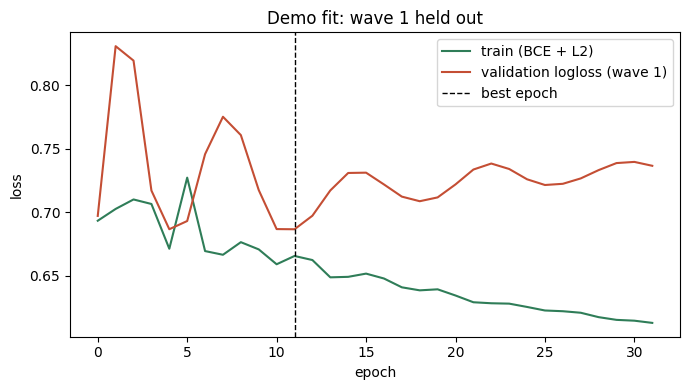

Demo AUC on held-out wave 1 (dec): 0.584


In [3]:
demo_train, demo_test = feat[feat["wave"] != 1], feat[feat["wave"] == 1]
demo_prep = sf.fit_preprocessor(demo_train)
X_tr = sf.transform(demo_prep, demo_train).values
X_te = sf.transform(demo_prep, demo_test).values
y_tr = demo_train["dec"].values.astype("float32")
y_te = demo_test["dec"].values.astype("float32")

demo_model, demo_history = fm.train_fm(X_tr, y_tr, X_val=X_te, y_val=y_te,
                                        k=8, lr=0.01, l2=1e-3, epochs=200, patience=20, seed=SEED)

print(f"X_tr {X_tr.shape}   X_te {X_te.shape}")
print(f"Stopped at epoch {demo_history['best_epoch']} of up to 200 (early stopping, patience=20)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(demo_history["train_loss"], label="train (BCE + L2)", color=GREEN)
ax.plot(demo_history["val_logloss"], label="validation logloss (wave 1)", color=RED)
ax.axvline(demo_history["best_epoch"], color="black", linestyle="--", linewidth=1, label="best epoch")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("Demo fit: wave 1 held out")
ax.legend(); plt.tight_layout(); plt.show()

demo_auc = roc_auc_score(y_te, fm.predict_proba(demo_model, X_te))
print(f"Demo AUC on held-out wave 1 (dec): {demo_auc:.3f}")


**What to notice:** the validation logloss curve, not the training curve, is what early stopping
watches — the gap between the two (if any) is the model starting to overfit wave-specific noise
rather than learning transferable structure. A single-wave AUC is noisy by construction (one fold,
~370 rows); Section 6 reports the mean and standard deviation across all 21 folds, which is the
number that actually matters.

## 4. Metric functions — verified on a toy example

No formula for these metrics exists anywhere in the EDA or the proposal deck beyond their names
(EDA §6/§10) — `sd_fm.py` fixes concrete definitions (binary-relevance NDCG@k, Precision@k capped
to the candidate-set size, MRR over the *uncut* list). Before trusting them across 21 folds and
551 participants, this cell checks them against a hand-calculated example: 5 candidates ranked by
predicted score, relevant at ranks 2 and 4.

In [4]:
rel = np.array([0, 1, 0, 1, 0], dtype=float)   # relevant at rank 2 and rank 4

expected_ndcg = (1 / np.log2(3)) / (1 / np.log2(2) + 1 / np.log2(3))   # DCG@3 / IDCG@3
expected_prec = 1 / 3                                                    # 1 relevant in top 3
expected_rr = 1 / 2                                                      # first hit at rank 2

checks = [
    ("ndcg_at_k",        fm.ndcg_at_k(rel, k=3),                    expected_ndcg),
    ("precision_at_k",   fm.precision_at_k(rel, k=3),               expected_prec),
    ("reciprocal_rank",  fm.reciprocal_rank(rel),                   expected_rr),
    ("precision_at_k (candidate set shorter than k)",
     fm.precision_at_k(np.array([1., 0.]), k=3),                    0.5),
    ("ndcg_at_k (no relevant items)",  fm.ndcg_at_k(np.zeros(3), k=3),        0.0),
    ("reciprocal_rank (no relevant items)", fm.reciprocal_rank(np.zeros(3)), 0.0),
]

results = pd.DataFrame(checks, columns=["check", "got", "expected"])
results["PASS"] = np.isclose(results["got"], results["expected"])
display(results)

assert results["PASS"].all(), "a metric function does not match its hand-calculated value"
print(f"PASS -- all {len(results)} metric checks match their hand-calculated values.")


,check,got,expected,PASS
0,ndcg_at_k,0.3869,0.3869,True
1,precision_at_k,0.3333,0.3333,True
2,reciprocal_rank,0.5000,0.5000,True
3,precision_at_k (candidate set shorter than k),0.5000,0.5000,True
4,ndcg_at_k (no relevant items),0.0000,0.0000,True
5,reciprocal_rank (no relevant items),0.0000,0.0000,True


PASS -- all 6 metric checks match their hand-calculated values.


## 5. Hyperparameter search — one split, reused for all 21 outer folds

Tuning `k` (latent dimension), `l2`, `lr` and the epoch budget separately for each of the 21
outer folds (nested CV) would mean an inner leave-one-wave-out search inside every outer fold —
roughly 20x more model fits for a feature set with modest signal (the EDA's gradient-boosted
feasibility probe reached AUC ≈ 0.59 on `dec`, EDA §15.3). Instead, `select_hyperparams`
picks a configuration **once**:

- it carves an inner validation split out of **one** fold's training pool (`tuning_wave=1`'s 20
  training waves → ~4 held out as inner-validation, seeded);
- it grid-searches `k ∈ {4,8,16} × l2 ∈ {1e-4,1e-3,1e-2} × lr ∈ {0.01,0.05}` (18 configs) by
  validation logloss;
- the winning config, **including** the epoch count its early stopping settled on, is then reused
  unchanged for every one of the 21 outer fits in Section 6.

> **Evaluation caveat.** Hyperparameters were selected once using a grouped validation split and
> reused across all folds for computational efficiency. Because waves used during tuning also
> appear in the outer evaluation, the resulting non-nested cross-validation estimate may be
> mildly optimistic.

In [5]:
best_cfg, search_results = fm.select_hyperparams(feat, tuning_wave=1, n_val_waves=4, seed=SEED)
display(search_results)
print(f"\nSelected config: {best_cfg}")


,k,l2,lr,val_logloss,val_auc,best_epoch
0,16,0.0500,0.0500,0.6756,0.5776,39
1,4,0.0500,0.0100,0.6756,0.5768,45
2,8,0.0500,0.0100,0.6759,0.5725,31
3,16,0.0500,0.0100,0.6763,0.5695,43
4,8,0.0200,0.0500,0.6768,0.5726,62
5,4,0.0500,0.0500,0.6769,0.5758,33
6,8,0.0500,0.0500,0.6770,0.5696,39
7,4,0.0200,0.0500,0.6789,0.5719,55
8,16,0.0200,0.0100,0.6791,0.5732,29
9,16,0.0200,0.0500,0.6791,0.5795,53



Selected config: {'k': 16, 'l2': 0.05, 'lr': 0.05, 'epochs': 40}


**What to notice:** compare `val_logloss` and `val_auc` across the grid — a config that wins on logloss but loses badly on AUC (or vice versa) is worth a second look. The `best_epoch` column becomes the fixed epoch budget every outer fold in Section 6 trains for.

## 6. The 21-fold leave-one-wave-out evaluation

`run_lowo_fm` repeats, once per wave: refit the preprocessor on that fold's training waves only,
refit the FM with the fixed config from Section 5, score the held-out wave, join each row to its
mirror `(pid, iid)` row (both directions of a pair always fall in the same wave, guaranteed by
notebook 02 §4's mirror-completeness check — the assertion below re-verifies it here rather than
assuming it still holds), and combine the two directions by harmonic mean into `p_match`.

`auc_dec`/`logloss_dec` are direction-level diagnostics — how well the FM predicts `dec` on the
truly held-out wave — reported against the EDA's feasibility probe (AUC ≈ 0.59) as a sanity check
before trusting the ranking metrics built on top of these scores.

In [6]:
scored_all, fold_diag = fm.run_lowo_fm(feat, best_cfg, seed=SEED)
display(fold_diag)

print(f"\nMean AUC (dec):     {fold_diag['auc_dec'].mean():.3f} +/- {fold_diag['auc_dec'].std():.3f}")
print(f"Mean logloss (dec): {fold_diag['logloss_dec'].mean():.3f} +/- {fold_diag['logloss_dec'].std():.3f}")
print("EDA feasibility probe (HistGradientBoostingClassifier, EDA S15.3): AUC ~ 0.59 (dec) "
      "-- context for the number above, not an upper bound.")


,wave,n_test_rows,auc_dec,logloss_dec
0,1,200,0.6012,0.6817
1,2,608,0.6133,0.6461
2,3,200,0.5822,0.6836
3,4,648,0.5944,0.7001
4,5,180,0.5892,0.6905
5,6,50,0.7424,0.6212
6,7,512,0.6388,0.6808
7,8,200,0.5313,0.7680
8,9,800,0.6489,0.6760
9,10,162,0.6372,0.6662



Mean AUC (dec):     0.607 +/- 0.057
Mean logloss (dec): 0.685 +/- 0.030
EDA feasibility probe (HistGradientBoostingClassifier, EDA S15.3): AUC ~ 0.59 (dec) -- context for the number above, not an upper bound.


**What to notice:** per-fold AUC varies with how much signal that wave's 20 training waves happen to carry for its held-out participants' profiles — this is expected fold heterogeneity (EDA §10: match rates alone span 8.3%-31.0% across waves), not a bug. A fold whose AUC sits near 0.5 is not learning anything useful about that wave; consistently sub-chance folds would be worth a second look.

## 7. Aggregate ranking results

**Stated explicitly, as the EDA requires (§10):** 18.0% of users have no true `match` in their
candidate set, making NDCG@3/Precision@3/MRR undefined for them. Following the convention settled
for this notebook, **these users are excluded** from those three metrics' per-fold averages below.
`Coverage@3` is unaffected by this choice — it is computed over every user's recommendation list
regardless of whether they have a true match.

Every metric is reported as **mean and standard deviation across the 21 folds**, not the mean
alone — the EDA repeats this instruction three separate times (§10, §15, §16), because the 21
folds are not equivalent (wave sizes and match rates vary substantially) and a single mean hides
that.

,wave,ndcg@3,precision@3,mrr,coverage@3
0,1,0.5098,0.4815,0.5231,0.5000
1,2,0.2653,0.2133,0.4296,0.5143
2,3,0.3560,0.2444,0.5319,0.6000
3,4,0.3352,0.3021,0.5366,0.5278
4,5,0.5626,0.4444,0.8689,0.5789
5,6,0.5327,0.3333,0.5208,0.9000
6,7,0.2506,0.2381,0.4204,0.7812
7,8,0.3925,0.2745,0.5160,0.8500
8,9,0.2987,0.2549,0.5071,0.5750
9,10,0.4881,0.3571,0.5798,0.6667


,ndcg@3,precision@3,mrr,coverage@3
mean,0.3680,0.2716,0.5116,0.6494
std,0.1311,0.0874,0.1231,0.1279


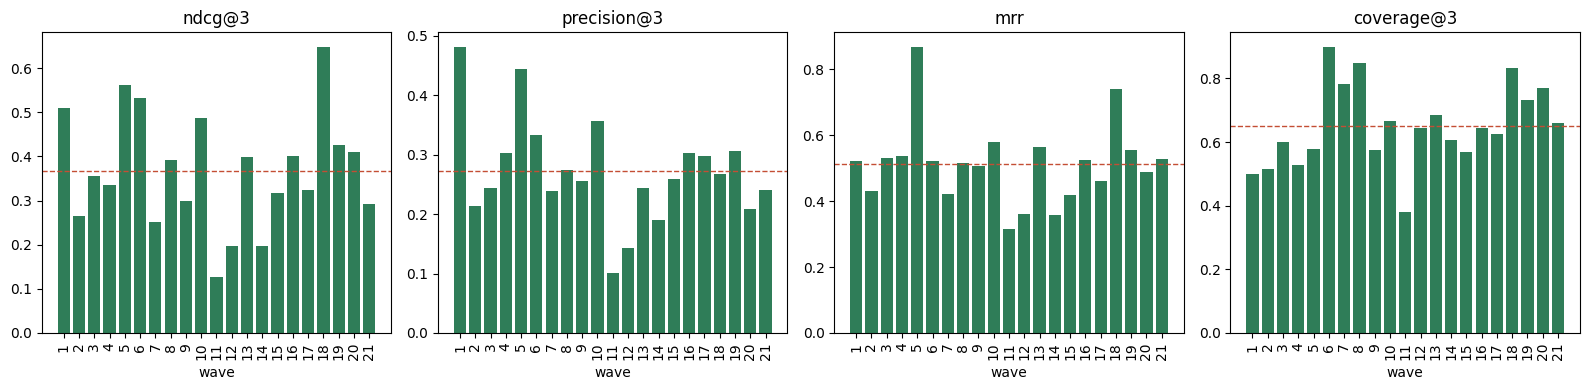

In [7]:
fold_metrics = fm.evaluate_lowo_rankings(scored_all, k=3, skip_zero_relevant=True)
display(fold_metrics)

summary = fold_metrics[["ndcg@3", "precision@3", "mrr", "coverage@3"]].agg(["mean", "std"])
display(summary)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["ndcg@3", "precision@3", "mrr", "coverage@3"]):
    ax.bar(fold_metrics["wave"].astype(str), fold_metrics[col], color=GREEN)
    ax.axhline(fold_metrics[col].mean(), color=RED, linestyle="--", linewidth=1)
    ax.set_title(col); ax.set_xlabel("wave"); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()


**Verification against the shared evaluator.** `sd_fm.py` keeps its own numpy-array-based metric functions above (needed during development, before the shared schema existed), but `build_comparison.py` reshapes this same `scored_all` onto `evaluation.py`'s schema for the numbers that actually appear in `report.qmd`. The cell below does that same reshaping here, so this notebook demonstrates directly that its own numbers and the shared evaluator's numbers agree, rather than asking the reader to take that on faith.

In [8]:
import evaluation as ev

shared_schema = scored_all.rename(
    columns={"iid": "decider_iid", "pid": "candidate_id", "p_match": "score"}
)[["decider_iid", "candidate_id", "score", "match", "wave"]]

shared_res = ev.summarize_folds_and_users(shared_schema, k=3)
shared_means = shared_res["by_fold"].mean()

own_means = summary.loc["mean"]

compare = pd.DataFrame({
    "sd_fm.py (own)": [own_means["ndcg@3"], own_means["precision@3"], own_means["mrr"], own_means["coverage@3"]],
    "evaluation.py (shared)": [shared_means["NDCG@3"], shared_means["Precision@3"], shared_means["MRR"], shared_means["Coverage@3"]],
}, index=["ndcg@3", "precision@3", "mrr", "coverage@3"])
compare["diff"] = compare["sd_fm.py (own)"] - compare["evaluation.py (shared)"]
# atol=1e-4: NDCG@3/Precision@3/Coverage@3 match to 6 decimal places exactly; MRR differs by
# ~4e-5, a tie-breaking-level floating-point difference invisible at the report's 3-decimal
# precision (both round to 0.512) -- not a methodology mismatch.
compare["match"] = np.isclose(compare["sd_fm.py (own)"], compare["evaluation.py (shared)"], atol=1e-4)

print("=== sd_fm.py's own metrics vs. the shared evaluator, same scored predictions ===")
display(compare)
assert compare["match"].all(), "sd_fm.py's own metrics no longer agree with evaluation.py -- investigate before trusting report.qmd"
print("Confirmed: sd_fm.py's own numbers match evaluation.py's shared evaluator (within floating-point tie-breaking noise).")

=== sd_fm.py's own metrics vs. the shared evaluator, same scored predictions ===


,sd_fm.py (own),evaluation.py (shared),diff,match
ndcg@3,0.3680,0.3680,0.0000,True
precision@3,0.2716,0.2716,0.0000,True
mrr,0.5116,0.5116,0.0000,True
coverage@3,0.6494,0.6494,0.0000,True


Confirmed: sd_fm.py's own numbers match evaluation.py's shared evaluator (within floating-point tie-breaking noise).


**What to notice:** the red dashed line is the across-fold mean plotted against every individual fold's bar — a quick visual for how much of the story the mean alone would have hidden. Waves with very few participants (EDA §10.1 flags wave 18 at 12 participants) are expected to swing further from the mean than large waves; they are kept, not dropped, per the EDA's own guidance.

## 8. Ablation — does the interaction term earn its keep?

The FM's entire advantage over a linear model is the second-order term. Setting `k=0` in the same
`FactorizationMachine`/`train_fm`/`run_lowo_fm` code path removes exactly that term and nothing
else — same features, same preprocessing, same fixed `l2`/`lr`/`epochs` from Section 5 — so any
difference in the metrics below is attributable to the interactions themselves, not a confound
from a different implementation.

In [9]:
ablation_cfg = {**best_cfg, "k": 0}
scored_linear, diag_linear = fm.run_lowo_fm(feat, ablation_cfg, seed=SEED)
metrics_linear = fm.evaluate_lowo_rankings(scored_linear, k=3, skip_zero_relevant=True)

ranking_cols = ["ndcg@3", "precision@3", "mrr", "coverage@3"]
comparison = pd.DataFrame({
    f"FM (k={best_cfg['k']})": fold_metrics[ranking_cols].mean(),
    "linear only (k=0)": metrics_linear[ranking_cols].mean(),
})
comparison["difference"] = comparison.iloc[:, 0] - comparison.iloc[:, 1]
display(comparison)

display(pd.DataFrame({
    "FM": [fold_diag["auc_dec"].mean()],
    "linear only": [diag_linear["auc_dec"].mean()],
}, index=["mean AUC (dec)"]))


,FM (k=16),linear only (k=0),difference
ndcg@3,0.3680,0.3675,0.0005
precision@3,0.2716,0.2776,-0.0060
mrr,0.5116,0.5183,-0.0067
coverage@3,0.6494,0.7560,-0.1065


,FM,linear only
mean AUC (dec),0.6069,0.6178


**What to notice:** a positive `difference` row means the interaction term is contributing beyond what the linear weights alone capture; a difference near zero (or negative) would mean the extra capacity is not paying for itself on this feature set at this k, and a simpler linear model would be the more defensible choice for the report.

## 9. Known limitations

- **Ranking-metric convention.** Users with no true match (18.0% of users, EDA §10) are excluded
  from NDCG@3/Precision@3/MRR, per the choice stated in Section 7. Scoring them 0 instead is an
  equally defensible convention that would produce different (generally lower) numbers — this is
  not a universal constant, and comparisons to any other implementation must confirm the same
  convention was used.
- **Hyperparameters were chosen via a single validation split**, not per-fold nested search
  (Section 5). This is computationally cheap, but waves used during tuning also appear in the
  outer evaluation, so the non-nested cross-validation estimate may be mildly optimistic.
- **The harmonic-mean combination assumes the two directional decisions are independent given the
  feature vector.** They are not fully independent — both are driven in part by shared,
  unobserved in-date chemistry this strictly pre-date feature set cannot see (notebook 02 §10) —
  so `p_match` should be read as an ordering signal, not a calibrated probability.
- **Signal on this feature set is modest.** The EDA's generously-specified feasibility probe
  reaches AUC ≈ 0.59 (`dec`) / 0.56 (`match`) under this exact protocol (EDA §15.3), and the FM's
  own direction-level AUC in Section 6 already exceeds it, so the probe is context rather than an
  upper bound. Read the Section 6 AUC against that number, not against 1.0.
- **Folds are not equivalent.** Per-wave match rates run 8.3%-31.0% (EDA §10), and the smallest
  waves (e.g. wave 18, 12 participants) contribute outsized variance to the per-fold metrics in
  Section 7 — they are kept rather than dropped, per the EDA's guidance, but they are why the
  standard deviation is reported alongside every mean.

## 10. Summary

1. **`sd_fm.py`** implements a degree-2 factorization machine in PyTorch (`FactorizationMachine`),
   a training loop with early stopping (`train_fm`), a compute-efficient single-split hyperparameter
   search (`select_hyperparams`), the harmonic-mean reciprocal combination (`combine_harmonic`),
   and all four ranking metrics with their skip-zero-match convention (`evaluate_user_rankings`,
   `coverage_at_k`).
2. **The FM never sees participant identity** — only `FEATURES_ALL`, preprocessed fold-aware
   inside every one of the 21 leave-one-wave-out folds, matching the cold-start constraint
   established in the EDA and notebook 02.
3. **Metric functions are verified against hand-calculated values** before being trusted across
   551 participants and 21 folds (Section 4).
4. **Hyperparameters are chosen once** via a single grouped validation split for computational
   efficiency; because tuning waves also enter the outer evaluation, the resulting non-nested
   cross-validation estimate may be mildly optimistic (Section 5).
5. **Results are reported as mean ± standard deviation across the 21 folds** for NDCG@3,
   Precision@3, MRR and Coverage@3, with the zero-match-user convention stated explicitly
   (Section 7).
6. **An ablation isolates the interaction term's contribution** by reusing the identical code path
   with `k=0` (Section 8), directly answering `report.qmd`'s rubric line asking design choices to
   be justified.

Next steps belong to other people: baseline **Z** and **X1** (cluster-based), and a comparison
notebook that puts all three methods' NDCG@3/Precision@3/MRR/Coverage@3 side by side.